# Analyse du data drift — Étape 3

**Objectif.** Vérifier si les clients qui arrivent en production ressemblent encore à ceux sur
lesquels le modèle a été entraîné. S'ils s'en éloignent (*data drift*), les prédictions peuvent
se dégrader sans qu'aucune erreur ne soit visible : l'API continue de répondre normalement.

**Pourquoi surveiller les données et pas directement la performance ?** En crédit, on ne sait si
un client rembourse que des mois après la décision. En attendant ces vraies étiquettes, la dérive
des données d'entrée est le **signal d'alerte précoce** disponible.

**Les deux jeux comparés**
| Jeu | Source | Rôle |
|---|---|---|
| Référence | Clients d'entraînement du projet 6 (`application_train`) | Ce que le modèle « connaît » |
| Production | Clients de `application_test`, envoyés un par un à l'API et journalisés en base | Ce qui arrive réellement |

**Plan**
1. Choisir les variables surveillées
2. Préparer les données de référence et de production
3. Rapport Evidently
4. Tests statistiques par type de variable (KS, chi²) et PSI
5. Visualisations (densités, corrélations)
6. Analyse opérationnelle (erreurs, latence)
7. Interprétation et plan d'action

## 1. Les variables surveillées

Le modèle utilise 800 variables. Les surveiller toutes serait illisible. On suit les variables qui **pèsent le plus dans les décisions** :
une dérive sur l'une d'elles a un impact direct sur les scores.

La liste est calculée par `ModeleScoring.variables_surveillees()` : l'API (qui ne journalise que
ces 12 variables) et ce notebook utilisent ainsi exactement la même définition.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RACINE = Path.cwd().parent        # le notebook est dans notebooks/ : la racine du projet est juste au-dessus
sys.path.append(str(RACINE))      # permet d'importer le code de l'API comme un module
from api.modele import ModeleScoring, lire_signature

modele = ModeleScoring()          # le MÊME modèle que l'API, empreinte SHA-256 vérifiée au chargement

### Mesurer l'importance : le *gain* plutôt que le *split*

LightGBM propose deux mesures :
- **split** : le nombre de fois où une variable sert à couper un arbre ;
- **gain** : de combien ces coupures ont réellement réduit l'erreur.

Une variable peut être utilisée très souvent pour des coupures marginales (beaucoup de *splits*,
peu de gain). Le gain mesure donc mieux ce qui **compte vraiment dans la décision** : c'est
la mesure retenue, déjà utilisée au projet 6 pour le graphique d'importance.


In [2]:
# Importance par "gain" : combien chaque variable a réellement fait baisser l'erreur du modèle
importances = pd.Series(
    modele.modele.booster_.feature_importance(importance_type="gain"),
    index=modele.variables,
).sort_values(ascending=False)

part = importances / importances.sum() * 100                     # en % du gain total : plus lisible
TYPES = {v["name"]: v["type"] for v in lire_signature()}          # double / long / boolean, lu dans MLmodel

TOP10 = part.head(10).index.tolist()
print(f"Le top 10 pèse {part.head(10).sum():.0f} % du gain total, sur {len(part)} variables")
pd.DataFrame({"part_gain_%": part.head(15).round(2),
              "type": [TYPES[c] for c in part.head(15).index]})


Le top 10 pèse 45 % du gain total, sur 800 variables


,part_gain_%,type
EXT_SOURCE_3,16.00,double
EXT_SOURCE_2,13.56,double
EXT_SOURCE_1,4.48,double
PAYMENT_RATE,2.92,double
DAYS_EMPLOYED,2.04,double
DAYS_BIRTH,1.47,long
INSTAL_DPD_MEAN,1.39,double
AMT_ANNUITY,1.18,double
CC_CNT_DRAWINGS_ATM_CURRENT_MEAN,0.99,double
APPROVED_CNT_PAYMENT_MEAN,0.98,double


**Lecture.** L'importance est très concentrée : 10 variables sur 800 portent **45 %** du gain
total, et les trois scores externes `EXT_SOURCE_1/2/3` en portent à eux seuls **34 %**.
Ce sont les variables à surveiller en priorité : si ces scores, fournis par des organismes
extérieurs, changent de méthode de calcul, le modèle dérive sans que rien ne change chez nous.

Toutes les variables du top 10 sont **numériques** (`double` ou `long`).


['EXT_SOURCE_3',
 'EXT_SOURCE_2',
 'EXT_SOURCE_1',
 'PAYMENT_RATE',
 'DAYS_EMPLOYED',
 'DAYS_BIRTH',
 'INSTAL_DPD_MEAN',
 'AMT_ANNUITY',
 'CC_CNT_DRAWINGS_ATM_CURRENT_MEAN',
 'APPROVED_CNT_PAYMENT_MEAN',
 'NAME_EDUCATION_TYPE_Higher_education',
 'CODE_GENDER_F']

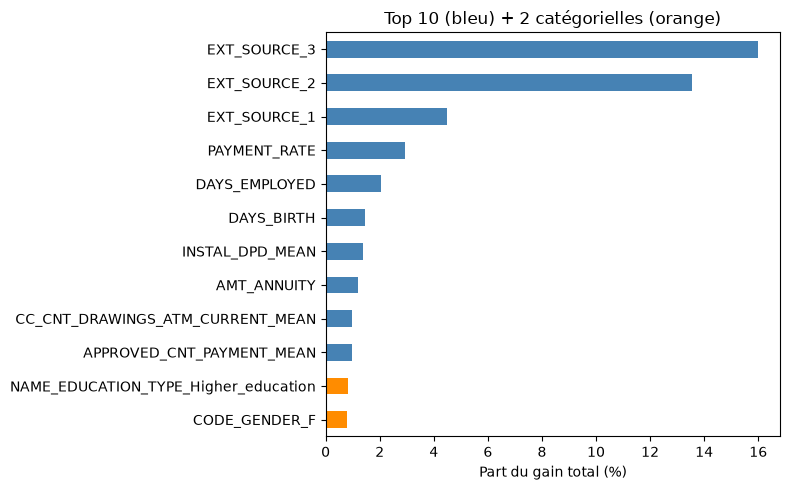

In [3]:
# Le top 10 est 100 % numérique : on ajoute les 2 variables 0/1 (issues du one-hot) les mieux classées
VARIABLES_SUIVIES = modele.variables_surveillees()   # la même liste que celle journalisée par l'API

top = part[VARIABLES_SUIVIES].sort_values()                       # tri croissant : la plus importante en haut du barh
couleurs = ["darkorange" if TYPES[c] == "boolean" else "steelblue" for c in top.index]
fig, ax = plt.subplots(figsize=(8, 5))
top.plot.barh(ax=ax, color=couleurs)
ax.set_xlabel("Part du gain total (%)")
ax.set_title("Top 10 (bleu) + 2 catégorielles (orange)")
fig.tight_layout()
VARIABLES_SUIVIES


**Pourquoi ajouter deux variables catégorielles ?** Le test de drift dépend du type de variable :
Kolmogorov-Smirnov pour les numériques, chi² pour les catégorielles. Le top 10 étant 100 %
numérique, on ajoute les deux variables 0/1 (issues du one-hot du projet 6) les mieux classées :
`NAME_EDUCATION_TYPE_Higher_education` (13e) et `CODE_GENDER_F` (15e).

**Point de vigilance : le genre.** Surveiller la répartition hommes/femmes en production est
sans risque au regard du RGPD : on compare des **proportions agrégées**, aucune donnée
individuelle n'est exposée. En revanche, le fait que le **modèle lui-même** utilise le genre
pour décider d'un crédit pose une question d'équité (risque de discrimination).

**Variables surveillées : 12** (10 numériques + 2 catégorielles), conservées dans `VARIABLES_SUIVIES`.


## 2. Les données de référence et de production

Préparées par `scripts/preparer_donnees.py`, qui reproduit à l'identique la préparation du projet 6
(table principale + agrégats des 5 tables d'historique, 800 variables).

- **Référence** (`data/reference.parquet`, 246 008 clients) : le `X_train` du projet 6, retrouvé
  grâce au même découpage (`test_size=0.2`, `stratify`, `random_state=42`). Contrôle : les
  probabilités des 3 premiers clients sont identiques à celles du projet 6 (0,0487 · 0,0807 · 0,1983).
- **Production** (`data/production.parquet`, 48 744 clients) : `application_test`, des clients que
  le modèle n'a jamais vus et dont on ne connaît pas l'issue (pas de colonne `TARGET`).

**Pourquoi préparer les deux jeux ensemble ?** L'encodage one-hot ne crée une colonne que pour les
catégories présentes. Trois catégories n'existent que dans le train (`CODE_GENDER = XNA`,
`NAME_INCOME_TYPE = Maternity leave`, `NAME_FAMILY_STATUS = Unknown`) : préparé seul, le jeu de
production n'aurait pas ces colonnes et l'API refuserait chaque client. En production réelle, où
les clients arrivent un par un, on alignerait chaque client sur la liste des variables du modèle.
